# Notebook 07 – Error analysis: model sai ở đâu và vì sao?

**Mục tiêu:** hiểu *kiểu lỗi* của model tốt nhất, chứ không chỉ nhìn một con số macro-F1. Đây là phần mà người chấm báo cáo và reviewer SemEval đọc kỹ nhất.

**Nội dung**
1. Chọn hệ thống tốt nhất (theo OOF) cho A và cho B
2. Confusion matrix và các kiểu lỗi của B
3. Lỗi theo đặc điểm của comment: độ dài, có nhắc nhóm bị nhắm không, tôn giáo, câu hỏi...
4. Lỗi theo video
5. So với TF-IDF: mẫu nào cả hai đều sai (= mẫu khó thật sự)?
6. Comment trùng nội dung nhưng khác nhãn (giới hạn trên của bài toán)
7. Lỗi "tự tin": model chắc chắn nhưng vẫn sai
8. Xuất file lỗi để cả nhóm đọc tay

⚠️ Notebook này in ra nguyên văn một số comment có nội dung xúc phạm, vì đó là dữ liệu của bài toán.

**P3 — 18/10/2026:** phân tích dự đoán của chiến lược được chọn bằng cross-fitting tầng quyết định. Đây là điểm phát triển, chưa phải nested CV độc lập toàn pipeline. Ghi chú P2 được giữ ở sample_30_B.csv; output P3 nằm trong thư mục riêng theo hash nguồn.


In [1]:
# Chạy trên Kaggle? Ô này chép bộ dữ liệu + code (dataset bạn đã upload) sang /kaggle/working
# vì /kaggle/input chỉ đọc được, không ghi được. Trên máy nhà ô này tự bỏ qua.
import os
import shutil
from pathlib import Path

if Path("/kaggle/input").exists():
    bundle = next(Path("/kaggle/input").rglob("SemEval2027_Task8")).parent
    work = Path("/kaggle/working/sqe")
    if not work.exists():
        shutil.copytree(bundle, work)
    os.chdir(work / "SemEval2027_Task8" / "notebooks")
    print("Kaggle – thư mục làm việc:", Path.cwd())

In [2]:
import re
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sqe").exists())
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, f1_score

from sqe.data import TASKS, load_en
from sqe.metrics import fold_scores
from sqe.results import InvalidOOFError, OOF_DIR, load_oof

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 160)
df = load_en()
OUT = ROOT / "outputs" / "error_analysis"
OUT.mkdir(parents=True, exist_ok=True)

## 1. Đọc chiến lược đã chọn ở P3

Notebook 08/script P3 chọn chiến lược. Notebook này dùng đúng dự đoán từng fold của chiến lược đó, không tự chọn lại model từ điểm toàn tập.


In [3]:
import json
from sqe.selection import export_review_table
from sqe.validation import validate_oof
recipe = json.loads((ROOT / "outputs/submissions/recipe.json").read_text(encoding="utf-8"))
manifest = json.loads((ROOT / "outputs/selection/manifest.json").read_text(encoding="utf-8"))
BEST = {t: recipe[t]["strategy"] for t in "AB"}
OUT = ROOT / "outputs/error_analysis/p3" / manifest["source_fingerprint"][:12]
OUT.mkdir(parents=True, exist_ok=True)
oof = {}
for t in "AB":
    frame = pd.read_csv(ROOT / recipe[t]["selected_strategy_oof"])
    validate_oof(frame, TASKS[t][1], df, TASKS[t][0])
    oof[t] = frame.merge(df, on=["StereoQueerEval_id", "video_id", "fold"], validate="one_to_one")
tfidf = {t: load_oof("tfidf_comment", t).set_index("StereoQueerEval_id")["y_pred"] for t in "AB"}
display(pd.read_csv(ROOT / "outputs/results/p3_strategies.csv"))
print("Phân tích chiến lược:", BEST, "| output:", OUT)


,subtask,strategy,macro_f1,f1_no,f1_yes,macro_f1_std,delta_vs_best_single,wins_vs_best_single,evaluation_scope,f1_yes_implicit,f1_yes_explicit,selected
0,A,best single,0.732,0.764,0.701,0.015,0.000e+00,0,development_oof_decision_crossfit,NaN,NaN,False
1,A,best single + bias,0.734,0.769,0.699,0.014,1.431e-03,3,development_oof_decision_crossfit,NaN,NaN,False
2,A,top-3 mean,0.742,0.771,0.713,0.010,9.510e-03,4,development_oof_decision_crossfit,NaN,NaN,False
3,A,top-3 mean + bias,0.740,0.763,0.717,0.009,7.210e-03,3,development_oof_decision_crossfit,NaN,NaN,False
4,A,greedy,0.745,0.777,0.714,0.014,1.312e-02,4,development_oof_decision_crossfit,NaN,NaN,False
5,A,greedy + bias,0.746,0.772,0.720,0.010,1.367e-02,4,development_oof_decision_crossfit,NaN,NaN,True
6,B,best single,0.601,0.750,NaN,0.026,0.000e+00,0,development_oof_decision_crossfit,0.431,0.620,False
7,B,best single + bias,0.596,0.734,NaN,0.016,-4.369e-03,2,development_oof_decision_crossfit,0.441,0.614,False
8,B,top-3 mean,0.604,0.742,NaN,0.016,3.711e-03,2,development_oof_decision_crossfit,0.454,0.617,False
9,B,top-3 mean + bias,0.607,0.739,NaN,0.013,6.839e-03,3,development_oof_decision_crossfit,0.463,0.620,True


Phân tích chiến lược: {'A': 'greedy + bias', 'B': 'top-3 mean + bias'} | output: C:\Users\Public\Documents\NĂM 3\NLP\Đồ án\SemEval2027_Task8\outputs\error_analysis\p3\2904d685b241


## 2. Confusion matrix và các kiểu lỗi

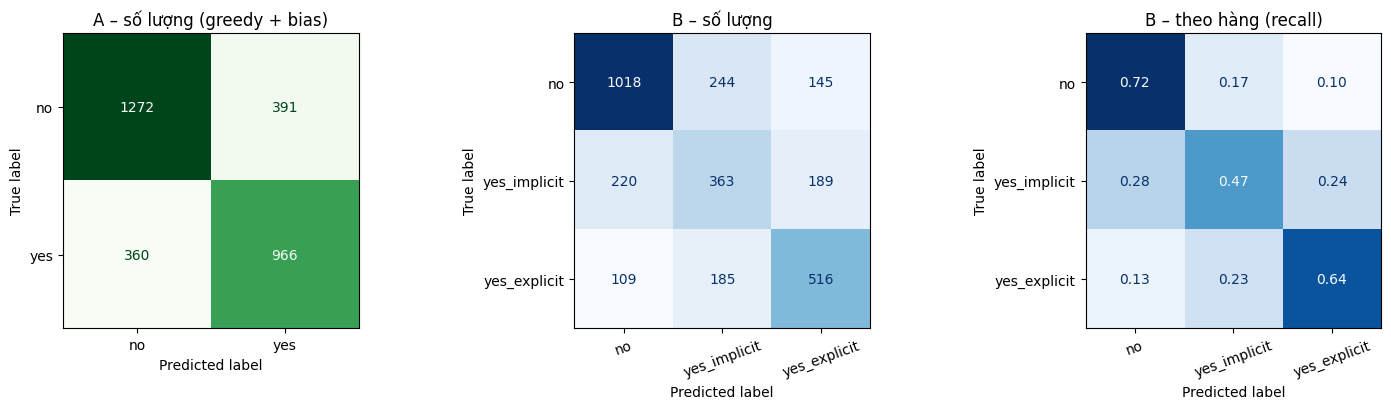

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ConfusionMatrixDisplay.from_predictions(oof["A"].y_true, oof["A"].y_pred, labels=TASKS["A"][1],
                                        ax=axes[0], colorbar=False, cmap="Greens")
axes[0].set_title(f"A – số lượng ({BEST['A']})")
for ax, norm, title in [(axes[1], None, "số lượng"), (axes[2], "true", "theo hàng (recall)")]:
    ConfusionMatrixDisplay.from_predictions(oof["B"].y_true, oof["B"].y_pred, labels=TASKS["B"][1], normalize=norm,
                                            values_format=".2f" if norm else "d", ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"B – {title}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(OUT / "confusion_best.png", dpi=150)
plt.show()

In [5]:
def error_type_B(y, p):
    if y == p:
        return "đúng"
    if y != "no" and p != "no":
        return "nhầm implicit ↔ explicit"
    if y != "no" and p == "no":
        return "bỏ sót hate (hate → no)"
    return "báo nhầm hate (no → hate)"


oof["B"]["error_type"] = [error_type_B(y, p) for y, p in zip(oof["B"].y_true, oof["B"].y_pred)]
et = oof["B"]["error_type"].value_counts()
errs = et.drop("đúng")
pd.DataFrame({"số mẫu": errs, "% trong tổng số lỗi": (errs / errs.sum() * 100).round(1)})

,số mẫu,% trong tổng số lỗi
error_type,,
báo nhầm hate (no → hate),389,35.6
nhầm implicit ↔ explicit,374,34.2
bỏ sót hate (hate → no),329,30.1


Nếu nhóm "nhầm implicit ↔ explicit" chiếm phần lớn thì điều đó khớp với EDA: hai lớp này gần như không tách được về mặt từ vựng. Mỗi lỗi kiểu này làm giảm F1 của *cả hai* lớp hate cùng lúc, nên ảnh hưởng mạnh đến macro-F1.

## 3. Lỗi theo đặc điểm của comment

Dùng lại các đặc trưng regex từ EDA (notebook 01). Với mỗi nhóm, tính macro-F1 của B và độ chính xác (accuracy). Nhóm nhỏ (n < 100) cho con số dao động nhiều, nên đọc kèm cột n.

In [6]:
FEATURES = {
    "nhắc identity (gay/trans/lgbt…)": r"\b(?:gays?|lesbians?|bi|bisexuals?|trans|transgender\w*|transsexual\w*|trans(?:wom[ae]n|m[ae]n)|queers?|homo\w*|lgbt\w*|non-?binary|intersex|asexual|tranny|trannies|fag\w*|dykes?)\b",
    "đại từ he/she/him/her": r"\b(?:he|him|his|she|her|hers)\b",
    "tôn giáo (god, sin, bible…)": r"\b(?:god|jesus|christ\w*|bible|sin|sins|sinful|sinner\w*|lord|church|allah|satan\w*|abomination|pray\w*|repent\w*|hell)\b",
    "sinh học (biology, dna, xx/xy…)": r"\b(?:biolog\w*|dna|chromosome\w*|xx|xy|genitals?|real (?:wom[ae]n|m[ae]n)|biological\w*)\b",
    "câu hỏi (?)": r"\?",
    "cười (😂, lol, lmao)": r"😂|🤣|\blol\b|\blmao\b|\bhaha\w*",
}
B = oof["B"]
labels_B = TASKS["B"][1]


def group_stats(mask):
    g = B[mask]
    return {"n": len(g), "macro_f1_B": f1_score(g.y_true, g.y_pred, labels=labels_B, average="macro", zero_division=0),
            "accuracy_B": (g.y_true == g.y_pred).mean(), "% nhãn hate": (g.y_true != "no").mean() * 100}


rows = []
for name, pat in FEATURES.items():
    has = B.yt_comment.str.lower().str.contains(pat, regex=True).to_numpy()
    rows.append({"đặc điểm": name, "có/không": "có", **group_stats(has)})
    rows.append({"đặc điểm": name, "có/không": "không", **group_stats(~has)})
pd.DataFrame(rows).set_index(["đặc điểm", "có/không"]).round(3)

n  macro_f1_B  accuracy_B  \
đặc điểm                        có/không                                 
nhắc identity (gay/trans/lgbt…) có        1108       0.568       0.676   
                                không     1881       0.605       0.610   
đại từ he/she/him/her           có         618       0.609       0.662   
                                không     2371       0.606       0.628   
tôn giáo (god, sin, bible…)     có         374       0.618       0.647   
                                không     2615       0.603       0.633   
sinh học (biology, dna, xx/xy…) có          90       0.504       0.522   
                                không     2899       0.611       0.638   
câu hỏi (?)                     có         486       0.579       0.621   
                                không     2503       0.613       0.637   
cười (😂, lol, lmao)             có         129       0.628       0.636   
                                không     2860       0.607       0.635   

                                          % nhãn hate  
đặc điểm                        có/không               
nhắc identity (gay/trans/lgbt…) có             42.419  
                                không          59.117  
đại từ he/she/him/her           có             49.029  
                                không          53.943  
tôn giáo (god, sin, bible…)     có             65.508  
                                không          51.128  
sinh học (biology, dna, xx/xy…) có             73.333  
                                không          52.294  
câu hỏi (?)                     có             49.177  
                                không          53.656  
cười (😂, lol, lmao)             có             52.713  
                                không          52.937

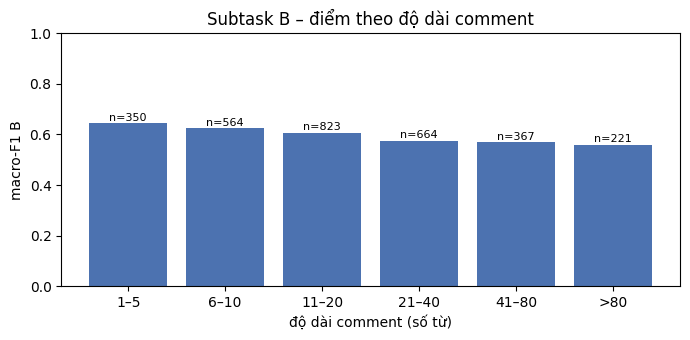

,số từ,n,macro_f1_B,accuracy_B,% nhãn hate
0,1–5,350,0.645,0.646,63.714
1,6–10,564,0.625,0.647,53.014
2,11–20,823,0.606,0.634,51.033
3,21–40,664,0.574,0.619,53.916
4,41–80,367,0.569,0.619,49.591
5,>80,221,0.559,0.661,45.249


In [7]:
n_words = B.yt_comment.str.split().str.len()
bins = pd.cut(n_words, [0, 5, 10, 20, 40, 80, 10_000], labels=["1–5", "6–10", "11–20", "21–40", "41–80", ">80"])
len_tab = pd.DataFrame([{"số từ": b, **group_stats((bins == b).to_numpy())} for b in bins.cat.categories])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(len_tab["số từ"], len_tab["macro_f1_B"], color="#4c72b0")
for i, r in len_tab.iterrows():
    ax.text(i, r.macro_f1_B + 0.01, f"n={r.n}", ha="center", fontsize=8)
ax.set_xlabel("độ dài comment (số từ)")
ax.set_ylabel("macro-F1 B")
ax.set_ylim(0, 1)
ax.set_title("Subtask B – điểm theo độ dài comment")
plt.tight_layout()
plt.savefig(OUT / "f1_by_length.png", dpi=150)
plt.show()
len_tab.round(3)

## 4. Lỗi theo video

Test chứa các video *mới*. Nếu model làm tốt ở một số video nhưng rất tệ ở số khác, điểm test sẽ phụ thuộc nhiều vào việc tập test rơi vào chủ đề nào.

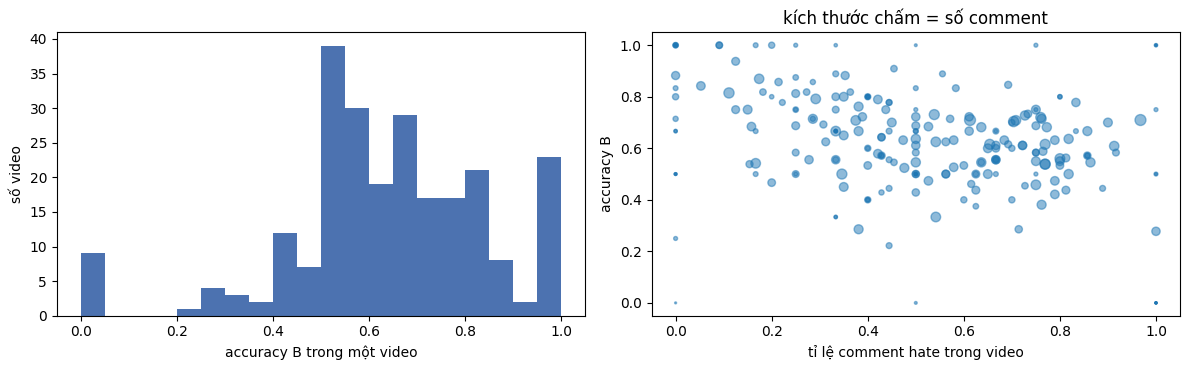

10 video (≥ 10 comment) model làm tệ nhất:


,n,title,accuracy,hate_rate
video_id,,,,
EN_v118,18,LGBT Content aimed at children to be banned in Hungary - [CHANNEL],0.278,1.000
EN_v066,21,Arguing the case for gay conversion therapy - Victoria Derbyshire,0.286,0.381
EN_v090,14,Hunter Schafer issued male passport,0.286,0.714
EN_v044,24,Supreme Court lets Trump block transgender people from choosing passport sex markers,0.333,0.542
EN_v023,21,Transgender boy wins girls wrestling title,0.381,0.762
EN_v122,10,Joel Osteen: scripture clear on gay marriage,0.400,0.700
EN_v073,10,The culture of coming out on YouTube,0.400,0.400
EN_v189,10,"Lawyer in Saudi trans student's suicide note had embassy links, [CHANNEL] finds | [CHANNEL]",0.400,0.600
EN_v075,19,SCOTUS issues blockbuster ruling on gender care for trans minors,0.421,0.789


In [8]:
vid = B.groupby("video_id").agg(n=("y_true", "size"), title=("yt_title", "first"),
                                accuracy=("error_type", lambda s: (s == "đúng").mean()),
                                hate_rate=("y_true", lambda s: (s != "no").mean()))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(vid.accuracy, bins=20, color="#4c72b0")
axes[0].set_xlabel("accuracy B trong một video")
axes[0].set_ylabel("số video")
axes[1].scatter(vid.hate_rate, vid.accuracy, s=vid.n * 2, alpha=0.5)
axes[1].set_xlabel("tỉ lệ comment hate trong video")
axes[1].set_ylabel("accuracy B")
axes[1].set_title("kích thước chấm = số comment")
plt.tight_layout()
plt.show()
print("10 video (≥ 10 comment) model làm tệ nhất:")
vid[vid.n >= 10].sort_values("accuracy").head(10)

## 5. So với TF-IDF: mẫu khó thật sự

Chia mẫu thành 4 nhóm theo việc hai model đúng hay sai. Nhóm **cả hai đều sai** là những mẫu khó với cả cách "đếm từ" lẫn cách "hiểu ngữ cảnh".

In [9]:
agree = {}
for t in "AB":
    o = oof[t]
    tr_ok = o.y_true == o.y_pred
    tf_ok = o.y_true.to_numpy() == tfidf[t].reindex(o.StereoQueerEval_id).to_numpy()
    agree[t] = pd.crosstab(pd.Series(tr_ok.values, name="transformer đúng"), pd.Series(tf_ok, name="TF-IDF đúng"))
    print(f"Subtask {t}")
    display(agree[t])

Subtask A


TF-IDF đúng,False,True
transformer đúng,,
False,514,237
True,371,1867


Subtask B


TF-IDF đúng,False,True
transformer đúng,,
False,730,362
True,583,1314


## 6. Comment giống nhau sau chuẩn hoá nhưng khác nhãn

Đây là các ca cần xem lại ngữ cảnh. Trùng sau chuẩn hoá không nhất thiết là cùng chuỗi token đầu vào; thống kê này chưa xác định được giới hạn trên của model.


In [10]:
def norm_text(s):
    s = re.sub(r"[^\w\s]", " ", s.lower())
    return re.sub(r"\s+", " ", s).strip()


d = df.assign(cn=df.yt_comment.map(norm_text))
dup = d[d.cn.duplicated(keep=False)]
conf = dup.groupby("cn").filter(lambda g: g.hate_speech.nunique() > 1 or g.stereotype.nunique() > 1)
print(f"Nhóm comment trùng sau chuẩn hoá: {dup.cn.nunique()} nhóm ({len(dup)} mẫu); "
      f"trong đó nhãn mâu thuẫn: {conf.cn.nunique()} nhóm ({len(conf)} mẫu, {len(conf) / len(df):.1%} dữ liệu)")
conf.sort_values("cn")[["video_id", "yt_title", "yt_comment", "stereotype", "hate_speech"]].head(20)

Nhóm comment trùng sau chuẩn hoá: 4 nhóm (8 mẫu); trong đó nhãn mâu thuẫn: 3 nhóm (6 mẫu, 0.2% dữ liệu)


,video_id,yt_title,yt_comment,stereotype,hate_speech
1419,EN_v077,Outrage at EU country’s homosexuality education bill,I stand with Hungary.,no,yes_implicit
1809,EN_v076,Hungary’s anti-LGBT law: How should the EU respond? - [CHANNEL] Newsnight,I stand with Hungary 🇷🇸🤝🇭🇺,no,yes_explicit
252,EN_v102,Mother of transgender teen weighs in ahead of Supreme Court hearing,That’s a man.,yes,yes_explicit
1359,EN_v151,Hear from the trans National Guard pilot falsely accused of flying helicopter in fatal collision,That's a man?,yes,yes_implicit
96,EN_v073,The culture of coming out on YouTube,Who gives a shit???,no,yes_explicit
1663,EN_v177,"[CHANNEL]: [CHANNEL] anchor Don Lemon talks coming out, abuse",Who gives a shit,no,yes_implicit


## 7. Lỗi "tự tin": model chắc chắn nhưng vẫn sai

Trước hết kiểm tra **độ tin cậy có đáng tin không**: gom mẫu theo xác suất cao nhất model đưa ra, xem độ chính xác thực tế. Sau đó liệt kê những mẫu sai mà model lại rất tự tin. Nhóm này hay chứa (a) mẫu cần context, (b) mỉa mai, hoặc (c) nhãn có thể bị gán nhầm.

In [11]:
P = B[[f"p_{l}" for l in labels_B]].to_numpy()
B["conf"] = P.max(1)
cb = pd.cut(B.conf, [0.33, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
calib = B.groupby(cb, observed=True).apply(lambda g: pd.Series({"n": len(g), "accuracy": (g.y_true == g.y_pred).mean(),
                                                               "conf_tb": g.conf.mean()}))
display(calib.round(3))
B[B.error_type != "đúng"].sort_values("conf", ascending=False)[
    ["yt_title", "yt_comment", "y_true", "y_pred", "conf"]].head(15)

,n,accuracy,conf_tb
conf,,,
"(0.33, 0.5]",240.0,0.417,0.453
"(0.5, 0.6]",420.0,0.448,0.546
"(0.6, 0.7]",409.0,0.511,0.652
"(0.7, 0.8]",437.0,0.549,0.751
"(0.8, 0.9]",534.0,0.642,0.853
"(0.9, 1.0]",949.0,0.861,0.950


,yt_title,yt_comment,y_true,y_pred,conf
12,Transgender federal employees say they face fear and discrimination under Trump,[CHANNEL] could include recent shootings committed by the trans community.,yes_implicit,no,0.982
743,LGBTQ activist Edwin Chiloba found dead in Kenya – [CHANNEL],Those who advocate for LGBTQ. Will face it rough.,yes_implicit,no,0.982
1817,"I’m a trans lawyer, here’s why I’m challenging the UK supreme court’s gender ruling",If you are a lawyer you should know that the Supreme Court hears cases on points of law and not 'individuals'. Oh and please don't appropriate 'nothing abou...,yes_implicit,no,0.981
2863,Trans people turn to crowdfunding to leave Florida,I’m interested to see how many people are still trans when the fad fizzles out,yes_implicit,no,0.979
200,LGBTQ activist Edwin Chiloba found dead in Kenya – [CHANNEL],LGBT life has the least importance,yes_explicit,no,0.979
360,Conservative party conference delegates discuss gay marriage,"Tory defenders of traditional marriage: John Profumo, John Major, Tim Yeo, David Mellor, Steve Norris, Hartley Booth, Piers Merchant, Jerry Hayes, Cecil Par...",yes_implicit,no,0.979
879,Pride: London's Gay Liberation front turns 50,"Regardless of your opinions on homosexuality and transgender-ism, no one should support a movement that aims to silence freedom of speech. The LGBT communi...",yes_explicit,no,0.979
905,How much do you know about LGBT history? - [CHANNEL],I know that you take up. 0.5% of the population as India willoughby said 'we only make up 0.5 per cent of the population' So why are we constantly talking a...,yes_implicit,no,0.978
674,Hungary’s anti-LGBT law: How should the EU respond? - [CHANNEL] Newsnight,"HALLELUYAH\nThis is beautiful and awesome, GOD IS with you my brothers and sister, stay strong and keep up the good work, GOD bless in JESUS mighty name.",yes_implicit,no,0.978
2785,"""Love will always win"" Orlando LGBT message to global gay community - [CHANNEL]",This was a great tragedy. Getting gay guys to believe in love is practically impossible with the community mind set. Maybe in 500 years from now.,yes_implicit,no,0.977


## 8. Xuất lỗi P3 mà giữ nguyên ghi chú P2

File mới nằm trong outputs/error_analysis/p3/<hash nguồn>/. Nếu file đã tồn tại cùng dữ liệu, giữ nguyên cả file và ghi chú; nếu nguồn khác thì dừng. File sample_30_B.csv của P2 không bị ghi đè, cũng không tự gắn ghi chú của model cũ sang lỗi của chiến lược khác.


In [12]:
cols = ["StereoQueerEval_id", "video_id", "yt_title", "yt_comment", "y_true", "y_pred"]
for t in "AB":
    e = oof[t][oof[t].y_true != oof[t].y_pred].copy()
    e["kieu_kho"] = ""
    e["source_model"] = "P3 " + BEST[t]
    pcols = [c for c in e.columns if c.startswith("p_")]
    keep = cols + (["error_type"] if t == "B" else []) + pcols + ["source_model", "kieu_kho"]
    export_review_table(e[keep], OUT / f"errors_{t}.csv")
    print(f"errors_{t}.csv: {len(e)} lỗi")
eB = B[B.error_type != "đúng"]
sample = pd.concat([g.sample(min(10, len(g)), random_state=42) for _, g in eB.groupby("error_type")])
sample = sample.assign(source_model="P3 " + BEST["B"], kieu_kho="")[cols + ["error_type", "source_model", "kieu_kho"]]
sample = export_review_table(sample, OUT / "sample_30_B.csv")
sample[["yt_comment", "y_true", "y_pred", "error_type"]].head(12)


errors_A.csv: 751 lỗi
errors_B.csv: 1092 lỗi


,yt_comment,y_true,y_pred,error_type
2195,"Typical AMERICAN bigot. Precisely why America will NEVER be great again, and NO ONE looks up to you.",no,yes_implicit,báo nhầm hate (no → hate)
400,if you don't want the conversion therapy then just don't take,no,yes_implicit,báo nhầm hate (no → hate)
1366,They are all hypocrites. Only care about themselves. Disgusting.,no,yes_explicit,báo nhầm hate (no → hate)
375,Lets freaking goooo,no,yes_implicit,báo nhầm hate (no → hate)
2709,False Prophet you appear to be.,no,yes_explicit,báo nhầm hate (no → hate)
1470,That’s not right,no,yes_explicit,báo nhầm hate (no → hate)
1216,This guy is trash hypocrite and sickening... Literally for the last 6-7 years the WOKE have been pushing for bills forcing people to use or not use certain ...,no,yes_implicit,báo nhầm hate (no → hate)
287,How much testosterone would a woman have to take to compete with men in the NFL ?,no,yes_implicit,báo nhầm hate (no → hate)
919,I feel so sorry for these gays....they need to leave the Mormon cult and move to San Fransisco!,no,yes_explicit,báo nhầm hate (no → hate)
1152,Homophobia is a mental disorder. And it’s Un Christian.,no,yes_explicit,báo nhầm hate (no → hate)


## 9. Kết luận

Phân tích tay P2: [P2_REVIEW.md](../outputs/error_analysis/P2_REVIEW.md), 30/30 mẫu MT đã đọc. Ba vấn đề được minh hoạ là xác định đối tượng, diễn giải lập trường trong câu và ranh giới implicit/explicit. Không suy tỷ lệ các nguyên nhân từ mẫu 10 lỗi mỗi nhóm.

P3: dùng bảng chiến lược và confusion matrix vừa tạo để mô tả hệ thống được chọn. Điểm là development CV của tầng quyết định, không phải điểm test. Recipe toàn OOF được fit sau lựa chọn có thể khác thành phần của từng fold đã chấm. Báo cáo lựa chọn nằm tại [P3_REVIEW.md](../outputs/selection/P3_REVIEW.md).
